# Machine Learning III End Semester Assessment
## Complete 100 Mark Solved Notebook

This notebook answers every question in the **May 2025 Machine Learning III ESA** and runs on the three supplied datasets.

| Section | Scope | Marks |
|---|---|---:|
| A | Silhouette, DBSCAN, PCA, matrix factorization and SVD | 20 |
| B | EDA, PCA, K-Means, hierarchical clustering and comparison | 40 |
| C | Apriori association rules and collaborative recommendations | 40 |
| **Total** | **All questions** | **100** |

The final appendix extends the paper with the remaining course outcomes: distance measures, DBSCAN, SVD, t-SNE, popularity/content recommenders, and FP-Growth.

## Section A Theory 20 marks

### Q1a Silhouette method and coefficient 5 marks

For a sample $i$ assigned to cluster $C_i$:

- $a(i)$ is the mean distance from $i$ to other samples in its own cluster. It measures **cohesion**.
- For every other cluster $C$, calculate the mean distance from $i$ to samples in $C$. The smallest is $b(i)$, measuring separation from the **nearest competing cluster**.
- The silhouette coefficient is

$$s(i)=\frac{b(i)-a(i)}{\max\{a(i),b(i)\}},\qquad -1\le s(i)\le1.$$

A value near **+1** means the point is compactly placed in its own cluster and far from alternatives. A value near **0** lies on a boundary. A negative value suggests a potentially wrong assignment. To choose $k$, fit clustering for a plausible range of cluster counts, calculate the mean $\bar{s}$, inspect the distribution of sample silhouettes, and prefer a solution with a high mean, few negative values, and reasonably balanced cluster widths. The highest score is evidence, not proof: business usefulness, stability, and interpretability also matter.

### Q1b DBSCAN working and key parameters 5 marks

DBSCAN defines clusters as connected high-density regions and labels isolated points as noise.

1. For an unvisited point, find its $\varepsilon$-neighbourhood $N_\varepsilon(p)=\{q:d(p,q)\le\varepsilon\}$.
2. If the neighbourhood contains at least `min_samples` points (including the point), it is a **core point** and starts or expands a cluster.
3. Recursively add all density-reachable core points and their neighbours.
4. A non-core point reached from a core point is a **border point**.
5. A point not density-reachable from any core point is labelled **noise** (`-1`).

The key parameters are **`eps`**, the neighbourhood radius; **`min_samples`**, the density threshold; and the **distance metric**. Small `eps` or large `min_samples` creates more noise; large `eps` may merge clusters. A k-distance plot helps select `eps`. Features must be scaled because distance magnitude directly controls neighbourhoods. DBSCAN can discover non-spherical clusters and needs no $k$, but varying density and high dimensionality are difficult.

### Q1c PCA steps, eigenvalues and eigenvectors 5 marks

1. Clean the data, retain numeric features, impute missing values, and standardize features when units differ.
2. Centre the data matrix $X$ and compute the covariance matrix $\Sigma=\frac{1}{n-1}X^TX$.
3. Solve $\Sigma v_j=\lambda_jv_j$. Each eigenvector $v_j$ is a principal direction; its eigenvalue $\lambda_j$ is the variance captured along that direction.
4. Sort eigenpairs by descending eigenvalue and choose the smallest $m$ satisfying $\sum_{j=1}^m\lambda_j/\sum_j\lambda_j\ge$ the required variance threshold.
5. Form $W=[v_1,\ldots,v_m]$ and project: $Z=XW$.

The principal components are orthogonal linear combinations. Eigenvectors supply the loading directions, while normalized eigenvalues supply the explained-variance ratios. PCA reduces redundancy and noise and supports visualization, but it is linear and scale-sensitive; signs of eigenvectors may flip without changing the solution.

### Q1d Matrix factorization and SVD in collaborative filtering 5 marks

Let $R\in\mathbb{R}^{m\times n}$ be a sparse user-item rating matrix. Matrix factorization approximates it with low-rank latent factors:

$$\hat R\approx PQ^T,\qquad \hat r_{ui}=\mu+b_u+b_i+p_u^Tq_i.$$

$p_u$ represents user preferences and $q_i$ represents item attributes learned from interaction patterns—not necessarily human-named features. Parameters minimize regularized error over observed ratings:

$$\min \sum_{(u,i)\in\Omega}(r_{ui}-\hat r_{ui})^2+\lambda(\|P\|_F^2+\|Q\|_F^2+\|b\|_2^2).$$

Classical SVD decomposes a complete matrix as $R=U\Sigma V^T$. Keeping the largest $k$ singular values gives the best rank-$k$ approximation in least-squares/Frobenius-norm terms. Real recommender matrices are sparse, so practical “SVD recommenders” optimize only observed ratings using SGD/ALS and include biases. Predicted scores rank unseen items. Cross-validation RMSE evaluates rating accuracy, while ranking metrics such as Precision@K, Recall@K and NDCG better evaluate top-N recommendations.

## Reproducible setup and supplied data

All random states are fixed. The notebook saves tables and figures under `artifacts/` and never modifies the source CSV files.

In [ ]:
from pathlib import Path
import json, math, random, time, warnings

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=DeprecationWarning)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA, TruncatedSVD
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.metrics import (silhouette_score, silhouette_samples, calinski_harabasz_score,
                             davies_bouldin_score, mean_squared_error)
from sklearn.model_selection import KFold
from sklearn.manifold import TSNE
from sklearn.neighbors import NearestNeighbors
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
from scipy.cluster.hierarchy import linkage, dendrogram, cophenet
from scipy.spatial.distance import pdist, euclidean, cityblock, minkowski
from yellowbrick.cluster import SilhouetteVisualizer
from mlxtend.preprocessing import TransactionEncoder
from mlxtend.frequent_patterns import apriori, fpgrowth, association_rules

SEED = 42
random.seed(SEED); np.random.seed(SEED)
sns.set_theme(style="whitegrid", context="notebook")

ROOT = next((p for p in [Path.cwd(), Path.home()/"Downloads"/"ML3_May_25"]
             if (p/"Mobile_clustering.csv").exists()), None)
if ROOT is None:
    raise FileNotFoundError("Run this notebook from the ML3_May_25 folder")

MOBILE_PATH = ROOT / "Mobile_clustering.csv"
BASKET_PATH = ROOT / "basket_data.csv"
RATINGS_PATH = ROOT / "Musical_Instruments_ratings.csv"
ARTIFACTS = ROOT / "artifacts"
ARTIFACTS.mkdir(exist_ok=True)
print("Working folder:", ROOT)
print("Libraries loaded successfully")

Working folder: /Users/somenathmandal/Downloads/ML3_May_25
Libraries loaded successfully


## Section B Clustering and dimensionality reduction 40 marks

### Q2a.1 EDA and essential preprocessing 7 marks

The mobile data are audited for shape, types, missing values, duplicates, constant columns, distribution and correlation. Median imputation is included defensively; standardization is essential because battery power, RAM, dimensions and binary indicators have different scales.

In [ ]:
mobile_raw = pd.read_csv(MOBILE_PATH)
audit = pd.DataFrame({
    "dtype": mobile_raw.dtypes.astype(str),
    "missing": mobile_raw.isna().sum(),
    "unique": mobile_raw.nunique(),
    "minimum": mobile_raw.min(numeric_only=True),
    "maximum": mobile_raw.max(numeric_only=True),
})
print("Shape:", mobile_raw.shape)
print("Duplicate rows:", int(mobile_raw.duplicated().sum()))
display(mobile_raw.head())
display(audit)
display(mobile_raw.describe().T)
assert mobile_raw.select_dtypes(exclude=np.number).empty, "Non-numeric columns require encoding"
assert not (mobile_raw.nunique() <= 1).any(), "Remove constant columns before PCA"

Shape: (3000, 20)
Duplicate rows: 0


/Users/somenathmandal/anaconda3/lib/python3.11/site-packages/pandas/core/dtypes/cast.py:1641: DeprecationWarning: np.find_common_type is deprecated.  Please use `np.result_type` or `np.promote_types`.
See https://numpy.org/devdocs/release/1.25.0-notes.html and the docs for more information.  (Deprecated NumPy 1.25)
  return np.find_common_type(types, [])
/Users/somenathmandal/anaconda3/lib/python3.11/site-packages/pandas/core/dtypes/cast.py:1641: DeprecationWarning: np.find_common_type is deprecated.  Please use `np.result_type` or `np.promote_types`.
See https://numpy.org/devdocs/release/1.25.0-notes.html and the docs for more information.  (Deprecated NumPy 1.25)
  return np.find_common_type(types, [])


,battery_power,blue,clock_speed,dual_sim,fc,four_g,int_memory,m_dep,mobile_wt,n_cores,pc,px_height,px_width,ram,sc_h,sc_w,talk_time,three_g,touch_screen,wifi
0,842,0,2.2,0,1,0,7,0.6,188,2,2,20,756,2549,9,7,19,0,0,1
1,1021,1,0.5,1,0,1,53,0.7,136,3,6,905,1988,2631,17,3,7,1,1,0
2,563,1,0.5,1,2,1,41,0.9,145,5,6,1263,1716,2603,11,2,9,1,1,0
3,615,1,2.5,0,0,0,10,0.8,131,6,9,1216,1786,2769,16,8,11,1,0,0
4,1821,1,1.2,0,13,1,44,0.6,141,2,14,1208,1212,1411,8,2,15,1,1,0


,dtype,missing,unique,minimum,maximum
battery_power,int64,0,1275,500.0,1999.0
blue,int64,0,2,0.0,1.0
clock_speed,float64,0,26,0.5,3.0
dual_sim,int64,0,2,0.0,1.0
fc,int64,0,20,0.0,19.0
four_g,int64,0,2,0.0,1.0
int_memory,int64,0,63,2.0,64.0
m_dep,float64,0,10,0.1,1.0
mobile_wt,int64,0,121,80.0,200.0
n_cores,int64,0,8,1.0,8.0


,count,mean,std,min,25%,50%,75%,max
battery_power,3000.0,1241.849000,437.063804,500.0,863.75,1232.0,1619.00,1999.0
blue,3000.0,0.502000,0.500079,0.0,0.00,1.0,1.00,1.0
clock_speed,3000.0,1.528467,0.820358,0.5,0.70,1.5,2.30,3.0
dual_sim,3000.0,0.512000,0.499939,0.0,0.00,1.0,1.00,1.0
fc,3000.0,4.404000,4.383742,0.0,1.00,3.0,7.00,19.0
four_g,3000.0,0.510000,0.499983,0.0,0.00,1.0,1.00,1.0
int_memory,3000.0,32.581667,18.152810,2.0,16.00,33.0,48.00,64.0
m_dep,3000.0,0.507000,0.285969,0.1,0.20,0.5,0.80,1.0
mobile_wt,3000.0,140.003000,35.213809,80.0,109.00,140.0,170.00,200.0
n_cores,3000.0,4.456333,2.289361,1.0,2.00,4.0,6.00,8.0


/Users/somenathmandal/anaconda3/lib/python3.11/site-packages/pandas/core/dtypes/cast.py:1641: DeprecationWarning: np.find_common_type is deprecated.  Please use `np.result_type` or `np.promote_types`.
See https://numpy.org/devdocs/release/1.25.0-notes.html and the docs for more information.  (Deprecated NumPy 1.25)
  return np.find_common_type(types, [])


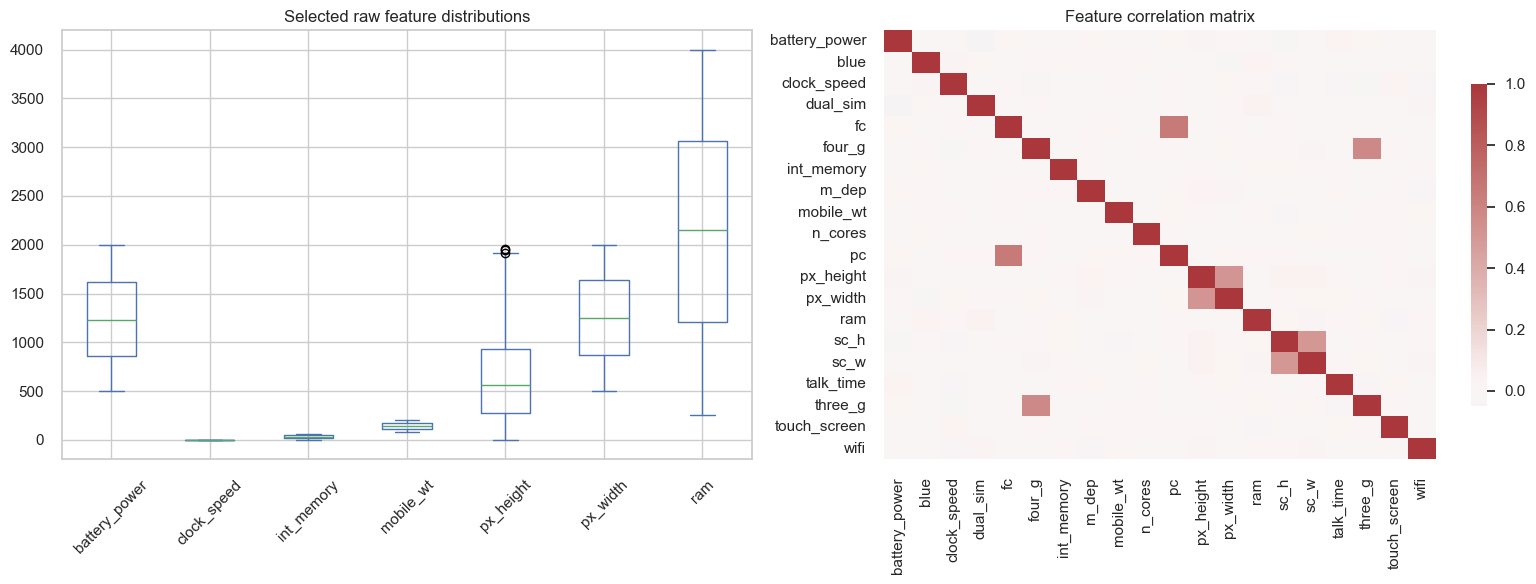

Post-processing means (max absolute): 4.026408835973901e-16
Post-processing standard deviations (range): (1.0, 1.0)


/Users/somenathmandal/anaconda3/lib/python3.11/site-packages/pandas/core/dtypes/cast.py:1641: DeprecationWarning: np.find_common_type is deprecated.  Please use `np.result_type` or `np.promote_types`.
See https://numpy.org/devdocs/release/1.25.0-notes.html and the docs for more information.  (Deprecated NumPy 1.25)
  return np.find_common_type(types, [])
/Users/somenathmandal/anaconda3/lib/python3.11/site-packages/pandas/core/dtypes/cast.py:1641: DeprecationWarning: np.find_common_type is deprecated.  Please use `np.result_type` or `np.promote_types`.
See https://numpy.org/devdocs/release/1.25.0-notes.html and the docs for more information.  (Deprecated NumPy 1.25)
  return np.find_common_type(types, [])
/Users/somenathmandal/anaconda3/lib/python3.11/site-packages/pandas/core/dtypes/cast.py:1641: DeprecationWarning: np.find_common_type is deprecated.  Please use `np.result_type` or `np.promote_types`.
See https://numpy.org/devdocs/release/1.25.0-notes.html and the docs for more informa

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
mobile_raw.hist(bins=25, ax=axes[0] if False else None)  # compact histograms rendered separately below
plt.close('all')

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
mobile_raw[["battery_power","clock_speed","int_memory","mobile_wt","px_height","px_width","ram"]].plot(
    kind="box", rot=45, ax=axes[0], title="Selected raw feature distributions")
sns.heatmap(mobile_raw.corr(numeric_only=True), cmap="vlag", center=0, ax=axes[1], cbar_kws={"shrink": .75})
axes[1].set_title("Feature correlation matrix")
plt.tight_layout()
eda_figure = ARTIFACTS / "mobile_eda.png"; plt.savefig(eda_figure, dpi=160, bbox_inches="tight"); plt.show()

imputer = SimpleImputer(strategy="median")
scaler = StandardScaler()
X_imputed = imputer.fit_transform(mobile_raw)
X_scaled = scaler.fit_transform(X_imputed)
standardized = pd.DataFrame(X_scaled, columns=mobile_raw.columns, index=mobile_raw.index)
print("Post-processing means (max absolute):", float(np.abs(standardized.mean()).max()))
print("Post-processing standard deviations (range):", tuple(np.round([standardized.std(ddof=0).min(), standardized.std(ddof=0).max()], 6)))

### Q2a.2 Minimum components preserving 90% variance 3 marks

Fit PCA to the standardized data and choose the first component index where cumulative explained variance reaches 0.90.

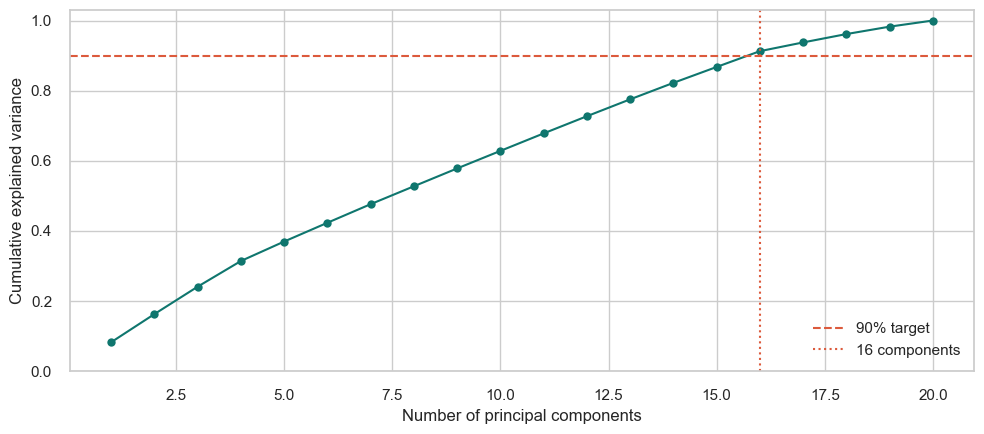

Minimum components for at least 90% variance: 16
Retained variance: 91.2684%
Reduced shape: (3000, 16)


In [ ]:
full_pca = PCA(svd_solver="full").fit(X_scaled)
cumulative_variance = np.cumsum(full_pca.explained_variance_ratio_)
n_components_90 = int(np.searchsorted(cumulative_variance, 0.90) + 1)

fig, ax = plt.subplots(figsize=(10, 4.5))
ax.plot(range(1, len(cumulative_variance)+1), cumulative_variance, marker="o", color="#0f766e")
ax.axhline(.90, color="#dc5a3c", linestyle="--", label="90% target")
ax.axvline(n_components_90, color="#dc5a3c", linestyle=":", label=f"{n_components_90} components")
ax.set(xlabel="Number of principal components", ylabel="Cumulative explained variance", ylim=(0, 1.03))
ax.legend(); plt.tight_layout()
pca_figure = ARTIFACTS / "pca_cumulative_variance.png"; plt.savefig(pca_figure, dpi=160, bbox_inches="tight"); plt.show()

pca90 = PCA(n_components=0.90, svd_solver="full")
X_pca90 = pca90.fit_transform(X_scaled)
print(f"Minimum components for at least 90% variance: {n_components_90}")
print(f"Retained variance: {pca90.explained_variance_ratio_.sum():.4%}")
print("Reduced shape:", X_pca90.shape)

### Q2a.3 Top five eigenvalues, eigenvectors and explained variance 4 marks

For standardized data, `explained_variance_` contains covariance eigenvalues and `components_` contains eigenvectors as rows. Eigenvector signs are arbitrary; reversing a component’s sign gives the same PCA subspace.

In [ ]:
top5_eigenvalues = full_pca.explained_variance_[:5]
top5_eigenvectors = pd.DataFrame(
    full_pca.components_[:5], index=[f"PC{i}" for i in range(1,6)], columns=mobile_raw.columns
)
top5_table = pd.DataFrame({
    "eigenvalue": top5_eigenvalues,
    "explained_variance_ratio": full_pca.explained_variance_ratio_[:5],
    "cumulative_ratio": np.cumsum(full_pca.explained_variance_ratio_[:5]),
}, index=top5_eigenvectors.index)
display(top5_table.round(6))
display(top5_eigenvectors.round(5))
top5_total_variance = float(full_pca.explained_variance_ratio_[:5].sum())
print(f"Total variance explained by top 5 PCs: {top5_total_variance:.4%}")
top5_table.to_csv(ARTIFACTS / "pca_top5_eigenvalues.csv")
top5_eigenvectors.to_csv(ARTIFACTS / "pca_top5_eigenvectors.csv")

,eigenvalue,explained_variance_ratio,cumulative_ratio
PC1,1.658712,0.082908,0.082908
PC2,1.604727,0.080210,0.163118
PC3,1.563084,0.078128,0.241246
PC4,1.464664,0.073209,0.314454
PC5,1.110347,0.055499,0.369953


,battery_power,blue,clock_speed,dual_sim,fc,four_g,int_memory,m_dep,mobile_wt,n_cores,pc,px_height,px_width,ram,sc_h,sc_w,talk_time,three_g,touch_screen,wifi
PC1,0.05256,-0.03638,0.02524,0.01109,0.69883,-0.01650,-0.04340,0.03875,0.04814,-0.00554,0.70029,0.01258,0.04163,-0.01324,-0.04357,-0.06780,-0.02099,-0.02480,0.00019,-0.02767
PC2,0.00894,0.03131,0.09167,0.00086,-0.03747,-0.56191,-0.00049,0.01874,0.02513,-0.00882,-0.04114,-0.22286,-0.23000,-0.05708,-0.35191,-0.36890,0.03468,-0.55078,0.01062,-0.01464
PC3,-0.00373,-0.04528,0.02616,-0.01129,-0.00784,-0.38790,0.03164,0.03730,-0.01313,-0.02567,-0.00092,0.50466,0.46871,-0.00514,0.31367,0.31021,0.06622,-0.40650,-0.02543,0.06382
PC4,0.11036,-0.06943,0.03652,-0.00218,-0.07452,0.15979,-0.05114,0.11124,0.02866,-0.03635,-0.05769,0.42757,0.46135,-0.06521,-0.51031,-0.49143,0.02651,0.15583,0.03821,-0.04285
PC5,-0.41777,0.19180,0.10790,0.54736,0.00916,0.00381,-0.00681,-0.19561,0.16900,-0.16520,0.00637,0.05362,0.06921,0.35173,-0.06019,-0.07058,-0.38792,-0.01403,-0.15806,0.25979


Total variance explained by top 5 PCs: 36.9953%


### Q2b Best K using PCA data and SilhouetteVisualizer 6 marks

The following cell fits K-Means for $k=2$ through $8$, renders Yellowbrick silhouette plots, and selects the maximum mean silhouette. A low absolute score must be reported as weak cluster structure even if it is the best tested option.

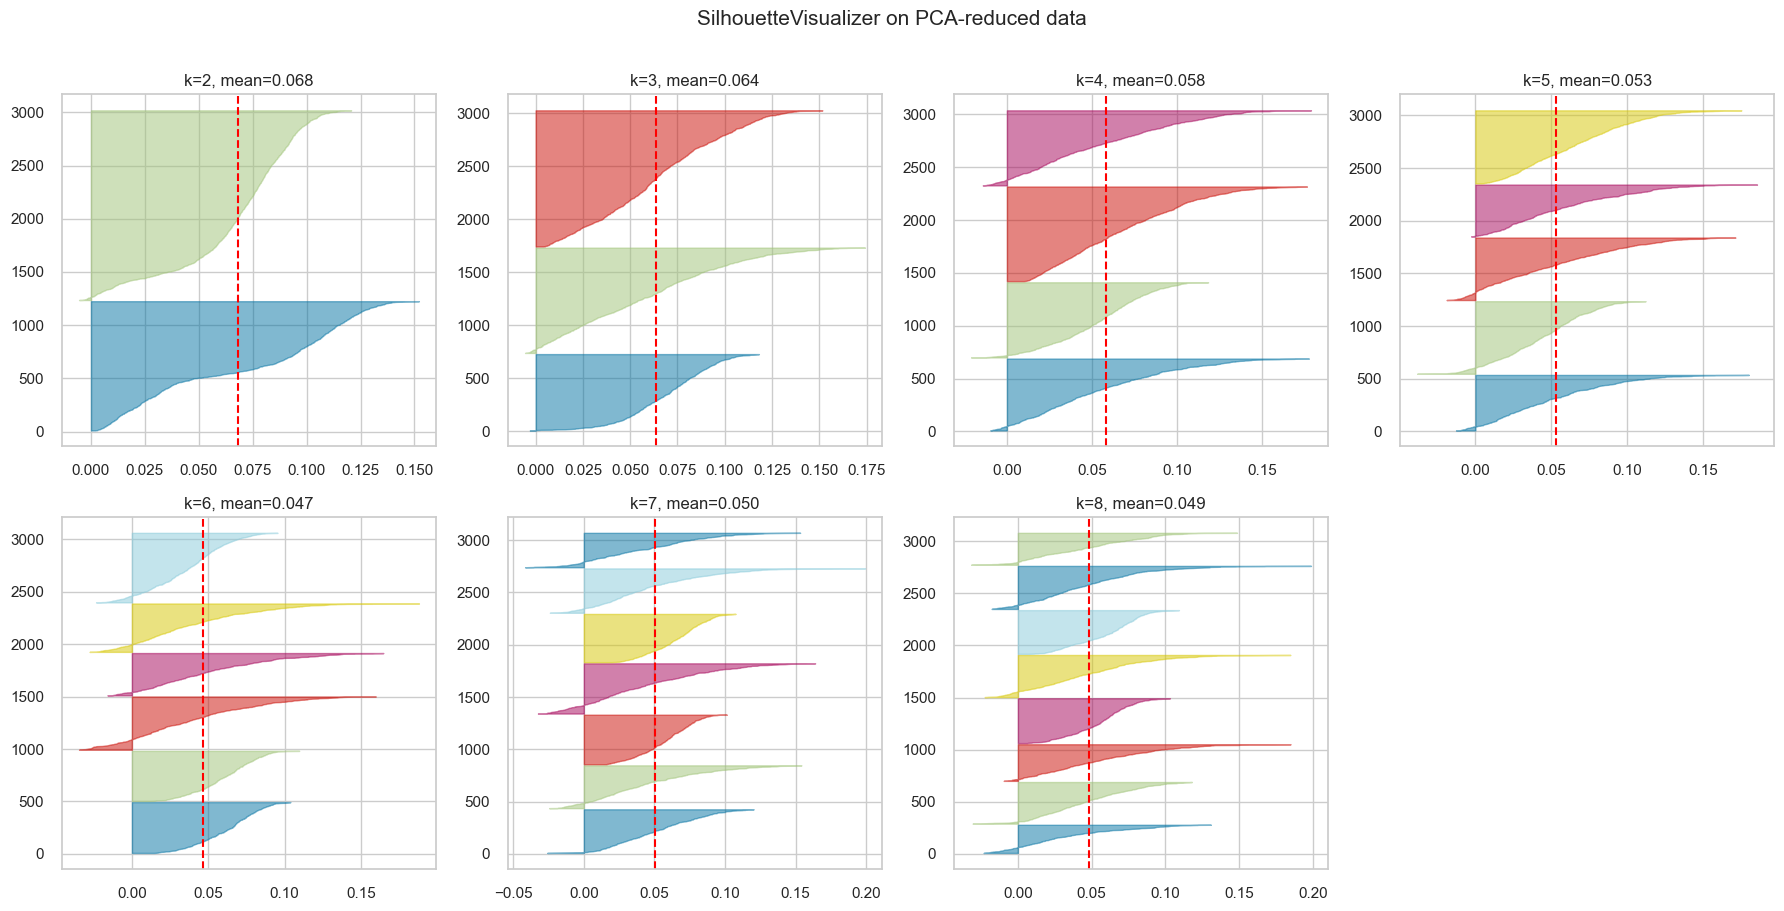

,k,silhouette,WCSS
0,2,0.06812,51035.78242
1,3,0.06378,48330.95339
2,4,0.05814,46526.96027
3,5,0.05318,45248.27730
4,6,0.04678,44409.65735
5,7,0.05011,43597.13752
6,8,0.04852,43038.81848


Best tested k: 2; silhouette=0.0681
Inference: the best score is low, so the data have weak natural separation in this representation.


In [ ]:
k_values = range(2, 9)
fig, axes = plt.subplots(2, 4, figsize=(18, 9))
silhouette_by_k, inertia_by_k = {}, {}
for ax, k in zip(axes.ravel(), k_values):
    model = KMeans(n_clusters=k, random_state=SEED, n_init=10)
    visualizer = SilhouetteVisualizer(model, colors="yellowbrick", ax=ax)
    visualizer.fit(X_pca90)
    silhouette_by_k[k] = float(visualizer.silhouette_score_)
    inertia_by_k[k] = float(model.inertia_)
    ax.set_title(f"k={k}, mean={visualizer.silhouette_score_:.3f}")
axes.ravel()[-1].axis("off")
plt.suptitle("SilhouetteVisualizer on PCA-reduced data", y=1.01, fontsize=15)
plt.tight_layout()
silhouette_figure = ARTIFACTS / "silhouette_visualizers.png"; plt.savefig(silhouette_figure, dpi=150, bbox_inches="tight"); plt.show()

best_k = max(silhouette_by_k, key=silhouette_by_k.get)
score_table = pd.DataFrame({"k": list(k_values), "silhouette": list(silhouette_by_k.values()), "WCSS": list(inertia_by_k.values())})
display(score_table.round(5))
print(f"Best tested k: {best_k}; silhouette={silhouette_by_k[best_k]:.4f}")
print("Inference: the best score is low, so the data have weak natural separation in this representation.")
score_table.to_csv(ARTIFACTS / "k_selection_metrics.csv", index=False)

### Q2c K-Means, labels and cluster feature means 5 marks

,size
0,1769
1,1231


,battery_power,blue,clock_speed,dual_sim,fc,four_g,int_memory,m_dep,mobile_wt,n_cores,pc,px_height,px_width,ram,sc_h,sc_w,talk_time,three_g,touch_screen,wifi
Cluster,,,,,,,,,,,,,,,,,,,,
0,-0.021,0.016,-0.037,0.031,0.021,0.71,-0.004,-0.009,0.008,-0.015,0.020,0.028,0.048,0.022,0.132,0.163,-0.049,0.562,0.023,-0.013
1,0.030,-0.023,0.053,-0.044,-0.030,-1.02,0.005,0.013,-0.012,0.021,-0.028,-0.041,-0.069,-0.032,-0.190,-0.234,0.070,-0.808,-0.032,0.019


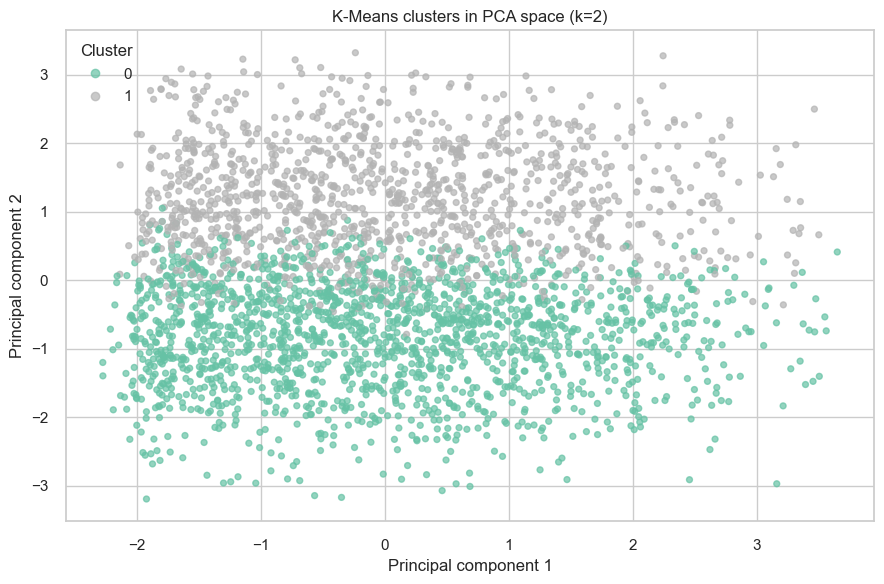

In [ ]:
kmeans_pca = KMeans(n_clusters=best_k, random_state=SEED, n_init=20)
pca_cluster_labels = kmeans_pca.fit_predict(X_pca90)
standardized_with_cluster = standardized.copy()
standardized_with_cluster["Cluster"] = pca_cluster_labels
cluster_profiles = standardized_with_cluster.groupby("Cluster").mean()
cluster_sizes = standardized_with_cluster["Cluster"].value_counts().sort_index().rename("size")
display(cluster_sizes.to_frame())
display(cluster_profiles.round(3))

fig, ax = plt.subplots(figsize=(9, 6))
scatter = ax.scatter(X_pca90[:,0], X_pca90[:,1], c=pca_cluster_labels, cmap="Set2", s=18, alpha=.7)
ax.set(xlabel="Principal component 1", ylabel="Principal component 2", title=f"K-Means clusters in PCA space (k={best_k})")
ax.legend(*scatter.legend_elements(), title="Cluster"); plt.tight_layout()
cluster_figure = ARTIFACTS / "kmeans_pca_clusters.png"; plt.savefig(cluster_figure, dpi=160, bbox_inches="tight"); plt.show()
cluster_profiles.to_csv(ARTIFACTS / "cluster_profiles_standardized.csv")

### Q2d Five linkage methods, 20-cluster dendrograms and cophenetic coefficient 7 marks

The dendrograms are truncated to the final 20 merged clusters for legibility. The cophenetic correlation compares original pairwise distances with dendrogram-implied distances; values closer to 1 preserve pairwise geometry better.

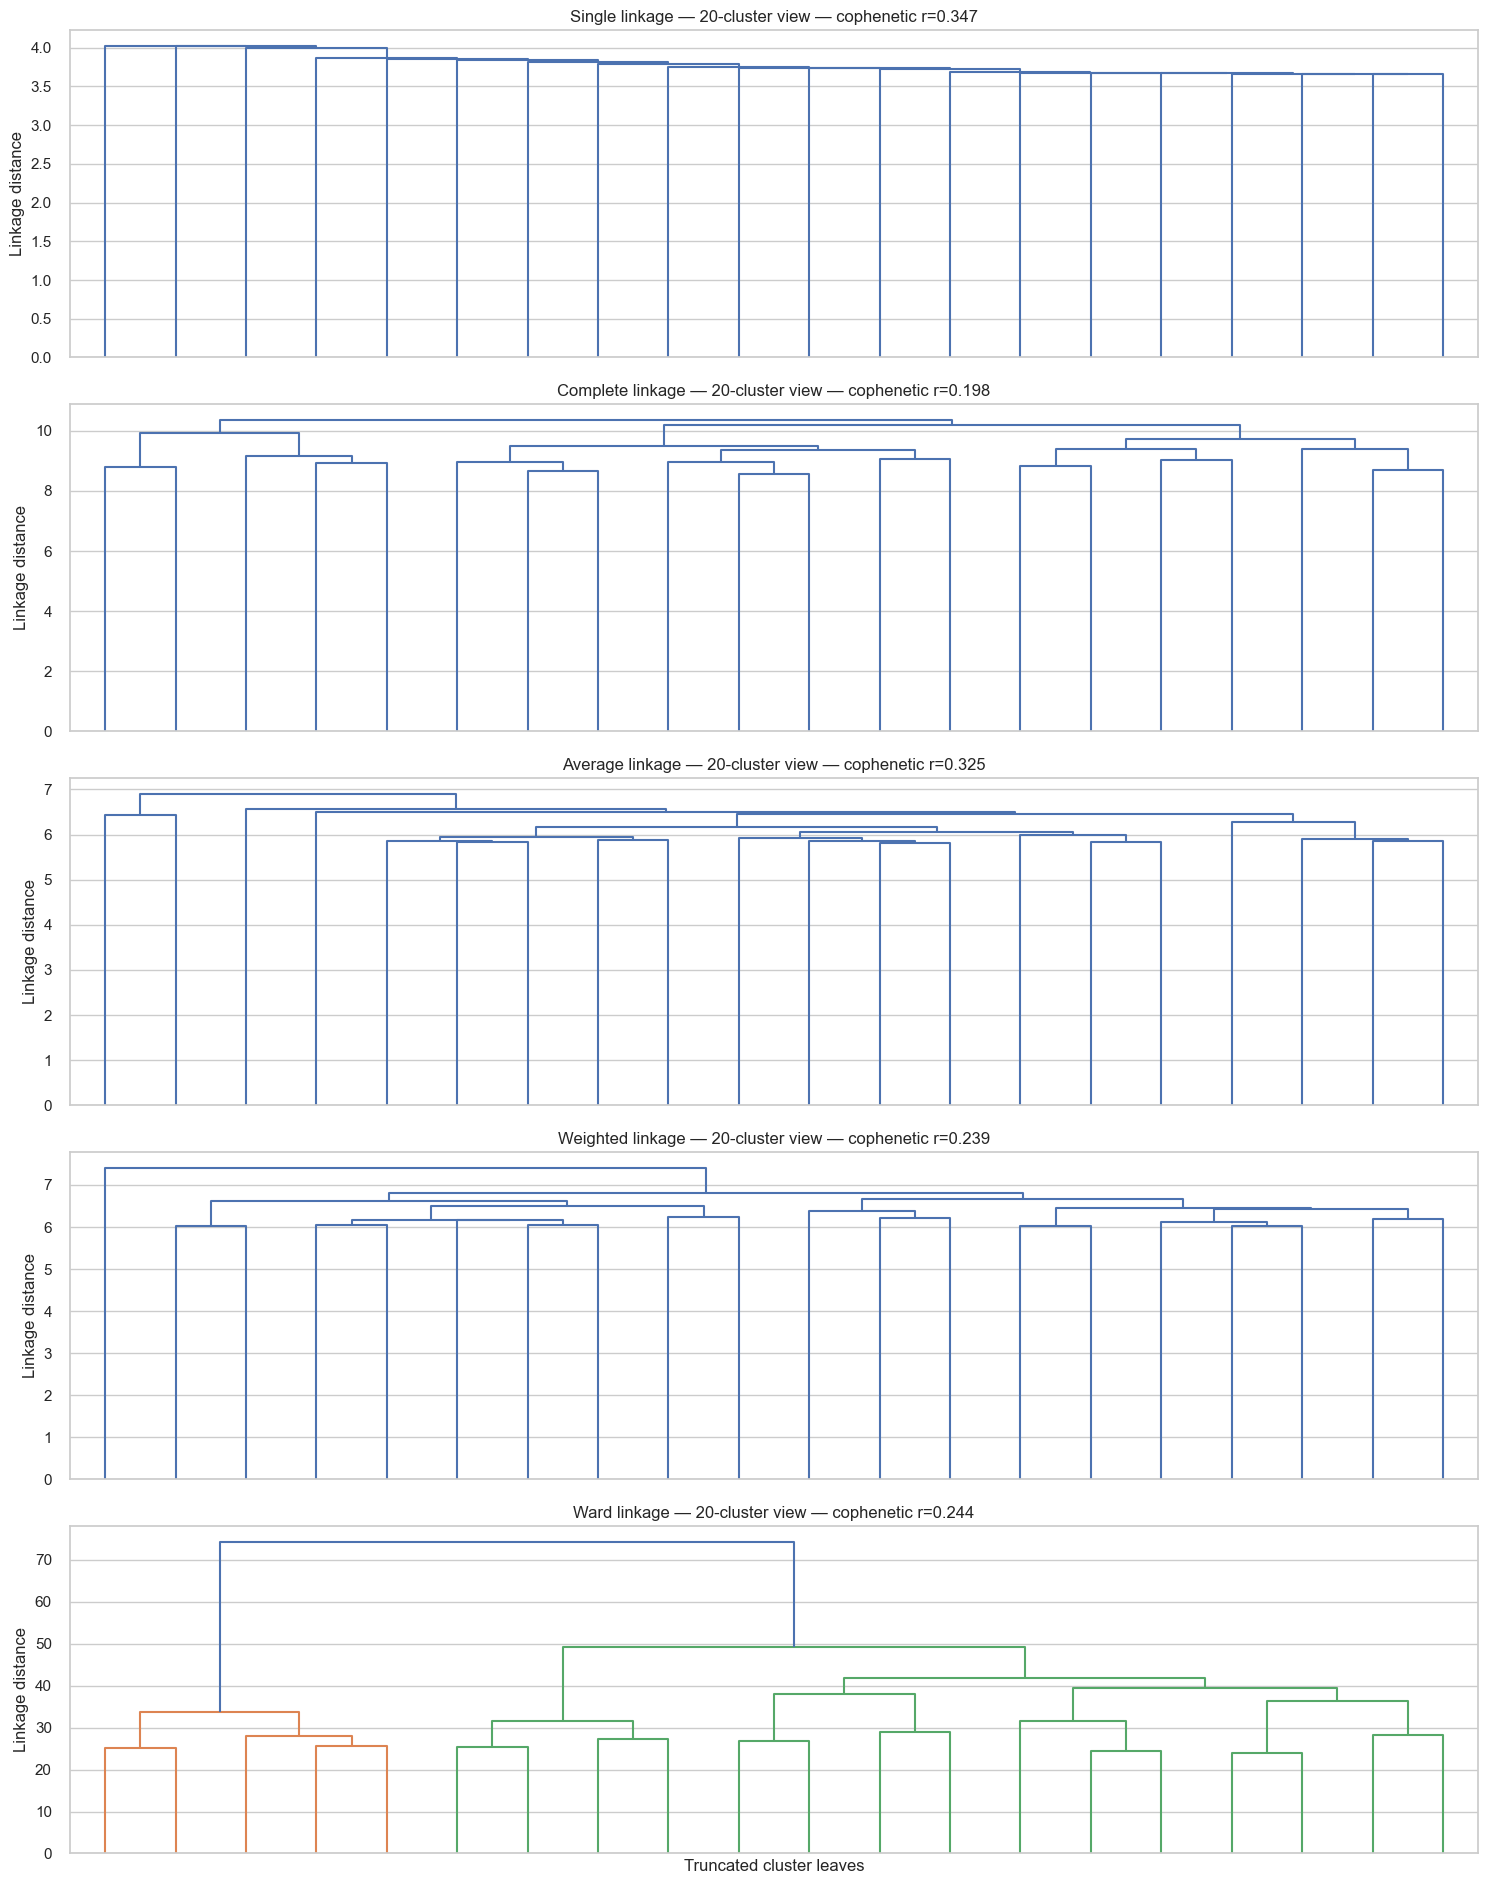

,linkage,cophenetic_correlation
0,single,0.34655
2,average,0.32513
4,ward,0.24411
3,weighted,0.23922
1,complete,0.19842


In [ ]:
linkage_methods = ["single", "complete", "average", "weighted", "ward"]
original_distances = pdist(X_pca90, metric="euclidean")
fig, axes = plt.subplots(5, 1, figsize=(15, 19))
cophenetic_results = []
for ax, method in zip(axes, linkage_methods):
    Z = linkage(X_pca90, method=method, metric="euclidean")
    coefficient, _ = cophenet(Z, original_distances)
    cophenetic_results.append({"linkage": method, "cophenetic_correlation": float(coefficient)})
    dendrogram(Z, truncate_mode="lastp", p=20, show_leaf_counts=True, no_labels=True, ax=ax, color_threshold=None)
    ax.set(title=f"{method.title()} linkage — 20-cluster view — cophenetic r={coefficient:.3f}", ylabel="Linkage distance")
axes[-1].set_xlabel("Truncated cluster leaves")
plt.tight_layout()
dendrogram_figure = ARTIFACTS / "five_linkage_dendrograms.png"; plt.savefig(dendrogram_figure, dpi=145, bbox_inches="tight"); plt.show()
cophenetic_table = pd.DataFrame(cophenetic_results).sort_values("cophenetic_correlation", ascending=False)
display(cophenetic_table.round(5))
cophenetic_table.to_csv(ARTIFACTS / "cophenetic_correlations.csv", index=False)

### Q2e K-Means vs Agglomerative on original standardized data 8 marks

Both models use the selected $k$. Higher Silhouette and Calinski-Harabasz are better; lower Davies-Bouldin is better. Metrics are internal validation measures and do not create ground-truth labels.

,silhouette,calinski_harabasz,davies_bouldin
model,,,
K-Means,0.06660,214.23505,3.71900
Agglomerative (Ward),0.07032,172.81891,3.39271


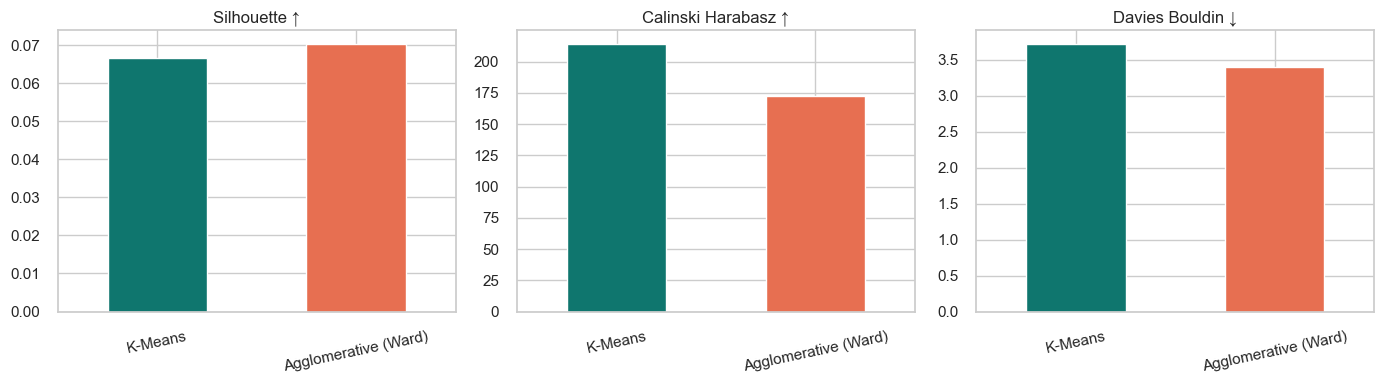

Inference: compare all three metrics; the low silhouettes confirm weak separation on the original feature space.


In [ ]:
original_models = {
    "K-Means": KMeans(n_clusters=best_k, random_state=SEED, n_init=20),
    "Agglomerative (Ward)": AgglomerativeClustering(n_clusters=best_k, linkage="ward"),
}
comparison_rows, original_labels = [], {}
for name, model in original_models.items():
    labels = model.fit_predict(X_scaled)
    original_labels[name] = labels
    comparison_rows.append({
        "model": name,
        "silhouette": silhouette_score(X_scaled, labels),
        "calinski_harabasz": calinski_harabasz_score(X_scaled, labels),
        "davies_bouldin": davies_bouldin_score(X_scaled, labels),
    })
clustering_comparison = pd.DataFrame(comparison_rows).set_index("model")
display(clustering_comparison.round(5))

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, metric, higher in zip(axes, clustering_comparison.columns, [True, True, False]):
    clustering_comparison[metric].plot(kind="bar", ax=ax, color=["#0f766e", "#e76f51"], rot=12)
    ax.set_title(metric.replace("_", " ").title() + (" ↑" if higher else " ↓")); ax.set_xlabel("")
plt.tight_layout()
comparison_figure = ARTIFACTS / "clustering_model_comparison.png"; plt.savefig(comparison_figure, dpi=160, bbox_inches="tight"); plt.show()
clustering_comparison.to_csv(ARTIFACTS / "clustering_model_comparison.csv")
print("Inference: compare all three metrics; the low silhouettes confirm weak separation on the original feature space.")

## Section C Association rules and recommendations 40 marks

### Q3a Apriori, minimum support 10%, lift greater than 2 20 marks

The basket file has **no header row**, so `header=None` is required. Every row becomes a transaction, then `TransactionEncoder` creates a Boolean item matrix. The paper’s thresholds are applied exactly. If no qualifying rules exist, an empty result is the correct empirical answer—not a reason to alter the requested thresholds silently.

In [ ]:
basket_raw = pd.read_csv(BASKET_PATH, header=None)
transactions = basket_raw.apply(
    lambda row: [str(x).strip() for x in row.dropna() if str(x).strip()], axis=1
).tolist()
encoder = TransactionEncoder()
basket_matrix = pd.DataFrame(encoder.fit(transactions).transform(transactions), columns=encoder.columns_)
print("Transactions:", len(transactions), "Unique items:", basket_matrix.shape[1])
print("Average basket size:", round(np.mean([len(t) for t in transactions]), 2))
display(basket_matrix.mean().sort_values(ascending=False).head(12).rename("support").to_frame())

frequent_10 = apriori(basket_matrix, min_support=0.10, use_colnames=True)
rules_10 = association_rules(frequent_10, metric="lift", min_threshold=2.0)
rule_columns = ["antecedents","consequents","support","confidence","lift"]
display(rules_10[rule_columns] if not rules_10.empty else pd.DataFrame(columns=rule_columns))
print(f"Frequent itemsets at 10% support: {len(frequent_10)}")
print(f"Rules with lift > 2: {len(rules_10)}")
if rules_10.empty:
    print("Inference: no item combination is frequent enough at 10% support to produce a lift>2 rule in this dataset.")

def rules_for_export(rules):
    result = rules.copy()
    for col in ["antecedents", "consequents"]:
        if col in result: result[col] = result[col].apply(lambda s: ", ".join(sorted(s)))
    return result

rules_for_export(rules_10).to_csv(ARTIFACTS / "association_rules_10pct_lift_gt2.csv", index=False)

Transactions: 7501 Unique items: 119
Average basket size: 3.91


,support
mineral water,0.238368
eggs,0.179709
spaghetti,0.174110
french fries,0.170911
chocolate,0.163845
green tea,0.132116
milk,0.129583
ground beef,0.098254
frozen vegetables,0.095321
pancakes,0.095054


,antecedents,consequents,support,confidence,lift


Frequent itemsets at 10% support: 7
Rules with lift > 2: 0
Inference: no item combination is frequent enough at 10% support to produce a lift>2 rule in this dataset.


In [ ]:
# Threshold sensitivity is supplementary and does not replace the required 10% answer.
frequent_03 = apriori(basket_matrix, min_support=0.03, use_colnames=True)
rules_03 = association_rules(frequent_03, metric="lift", min_threshold=2.0).sort_values("lift", ascending=False)
display(rules_03[rule_columns].head(10))
rules_for_export(rules_03).to_csv(ARTIFACTS / "association_rules_sensitivity_3pct.csv", index=False)

t0 = time.perf_counter(); apriori_03 = apriori(basket_matrix, min_support=.03, use_colnames=True); apriori_seconds = time.perf_counter()-t0
t0 = time.perf_counter(); fpgrowth_03 = fpgrowth(basket_matrix, min_support=.03, use_colnames=True); fpgrowth_seconds = time.perf_counter()-t0
algorithm_timing = pd.DataFrame({"algorithm":["Apriori","FP-Growth"], "itemsets":[len(apriori_03),len(fpgrowth_03)], "seconds":[apriori_seconds,fpgrowth_seconds]})
display(algorithm_timing.round(5))
algorithm_timing.to_csv(ARTIFACTS / "apriori_vs_fpgrowth.csv", index=False)

,antecedents,consequents,support,confidence,lift
1,(spaghetti),(ground beef),0.039195,0.225115,2.291162
0,(ground beef),(spaghetti),0.039195,0.398915,2.291162


,algorithm,itemsets,seconds
0,Apriori,54,0.01713
1,FP-Growth,54,0.02720


### Q3b Collaborative recommendation, top five items and 3-fold RMSE 20 marks

The raw file is highly sparse: most users rate very few items. For an estimable explicit-feedback model, the code retains users with at least 15 ratings and globally popular items with at least 20 ratings. The thresholds are stated, reproducible, and applied before cross-validation. A bias-aware Funk-SVD model learns latent factors using only observed ratings.

In [ ]:
ratings = pd.read_csv(RATINGS_PATH, dtype={"UserID":"string","ItemID":"string","Rating":"float32","Timestamp":"int64"})
user_counts = ratings["UserID"].value_counts()
item_counts = ratings["ItemID"].value_counts()
active_users = user_counts[user_counts >= 15].index
popular_items = item_counts[item_counts >= 20].index
ratings_model = ratings[ratings.UserID.isin(active_users) & ratings.ItemID.isin(popular_items)].reset_index(drop=True)

rating_audit = pd.Series({
    "raw_ratings": len(ratings), "raw_users": ratings.UserID.nunique(), "raw_items": ratings.ItemID.nunique(),
    "model_ratings": len(ratings_model), "model_users": ratings_model.UserID.nunique(), "model_items": ratings_model.ItemID.nunique(),
    "global_mean_rating": ratings.Rating.mean(),
})
display(rating_audit.to_frame("value"))
assert len(ratings_model) > 0 and ratings_model.UserID.nunique() > 1

/Users/somenathmandal/anaconda3/lib/python3.11/site-packages/pandas/core/algorithms.py:522: DeprecationWarning: np.find_common_type is deprecated.  Please use `np.result_type` or `np.promote_types`.
See https://numpy.org/devdocs/release/1.25.0-notes.html and the docs for more information.  (Deprecated NumPy 1.25)
  common = np.find_common_type([values.dtype, comps_array.dtype], [])
/Users/somenathmandal/anaconda3/lib/python3.11/site-packages/pandas/core/algorithms.py:522: DeprecationWarning: np.find_common_type is deprecated.  Please use `np.result_type` or `np.promote_types`.
See https://numpy.org/devdocs/release/1.25.0-notes.html and the docs for more information.  (Deprecated NumPy 1.25)
  common = np.find_common_type([values.dtype, comps_array.dtype], [])


,value
raw_ratings,500176.00000
raw_users,339231.00000
raw_items,83046.00000
model_ratings,7988.00000
model_users,827.00000
model_items,2554.00000
global_mean_rating,4.24435


In [ ]:
class BiasedMatrixFactorization:
    # Explicit-feedback matrix factorization trained with SGD.
    def __init__(self, n_factors=16, epochs=8, learning_rate=.01, regularization=.05, seed=42):
        self.n_factors, self.epochs = n_factors, epochs
        self.learning_rate, self.regularization, self.seed = learning_rate, regularization, seed

    def fit(self, frame):
        self.user_map = {u:i for i,u in enumerate(frame.UserID.unique())}
        self.item_map = {x:i for i,x in enumerate(frame.ItemID.unique())}
        self.global_mean = float(frame.Rating.mean())
        rng = np.random.default_rng(self.seed)
        self.user_bias = np.zeros(len(self.user_map)); self.item_bias = np.zeros(len(self.item_map))
        self.user_factors = rng.normal(0, .1, (len(self.user_map), self.n_factors))
        self.item_factors = rng.normal(0, .1, (len(self.item_map), self.n_factors))
        rows = [(self.user_map[u], self.item_map[i], float(r))
                for u,i,r in frame[["UserID","ItemID","Rating"]].itertuples(index=False, name=None)]
        lr, reg = self.learning_rate, self.regularization
        for _ in range(self.epochs):
            rng.shuffle(rows)
            for u, i, rating in rows:
                estimate = self.global_mean + self.user_bias[u] + self.item_bias[i] + self.user_factors[u] @ self.item_factors[i]
                error = rating - estimate
                old_user = self.user_factors[u].copy()
                self.user_bias[u] += lr * (error - reg*self.user_bias[u])
                self.item_bias[i] += lr * (error - reg*self.item_bias[i])
                self.user_factors[u] += lr * (error*self.item_factors[i] - reg*self.user_factors[u])
                self.item_factors[i] += lr * (error*old_user - reg*self.item_factors[i])
        return self

    def predict(self, user_id, item_id, clip=True):
        value = self.global_mean
        if user_id in self.user_map: value += self.user_bias[self.user_map[user_id]]
        if item_id in self.item_map: value += self.item_bias[self.item_map[item_id]]
        if user_id in self.user_map and item_id in self.item_map:
            value += self.user_factors[self.user_map[user_id]] @ self.item_factors[self.item_map[item_id]]
        return float(np.clip(value, 1, 5) if clip else value)

kfold = KFold(n_splits=3, shuffle=True, random_state=SEED)
fold_results = []
for fold, (train_idx, test_idx) in enumerate(kfold.split(ratings_model), 1):
    train_fold, test_fold = ratings_model.iloc[train_idx], ratings_model.iloc[test_idx]
    model = BiasedMatrixFactorization(seed=SEED+fold).fit(train_fold)
    predictions = np.array([model.predict(u,i) for u,i in test_fold[["UserID","ItemID"]].itertuples(index=False, name=None)])
    rmse = mean_squared_error(test_fold.Rating.to_numpy(), predictions, squared=False)
    fold_results.append({"fold":fold, "RMSE":rmse})

cv_results = pd.DataFrame(fold_results)
display(cv_results.round(5))
print(f"Mean 3-fold RMSE: {cv_results.RMSE.mean():.4f} ± {cv_results.RMSE.std(ddof=1):.4f}")
cv_results.to_csv(ARTIFACTS / "recommender_3fold_rmse.csv", index=False)

,fold,RMSE
0,1,0.94167
1,2,0.90384
2,3,0.93751


Mean 3-fold RMSE: 0.9277 ± 0.0207


In [ ]:
final_recommender = BiasedMatrixFactorization(epochs=12, seed=SEED).fit(ratings_model)
TARGET_USER = ratings_model.UserID.value_counts().index[0]  # reproducible active user
seen_items = set(ratings_model.loc[ratings_model.UserID == TARGET_USER, "ItemID"])
candidate_items = [item for item in ratings_model.ItemID.unique() if item not in seen_items]
recommendation_scores = [(item, final_recommender.predict(TARGET_USER, item, clip=False)) for item in candidate_items]
top5 = sorted(recommendation_scores, key=lambda x: x[1], reverse=True)[:5]
top5_recommendations = pd.DataFrame(top5, columns=["ItemID","predicted_score_raw"])
top5_recommendations["predicted_rating_clipped"] = top5_recommendations.predicted_score_raw.clip(1,5)
top5_recommendations["rating_count"] = top5_recommendations.ItemID.map(item_counts).astype(int)
print("Target user:", TARGET_USER, "Known ratings in modelling data:", len(seen_items))
display(top5_recommendations.round(4))
top5_recommendations.to_csv(ARTIFACTS / "top5_collaborative_recommendations.csv", index=False)

Target user: A2NYK9KWFMJV4Y Known ratings in modelling data: 72


,ItemID,predicted_score_raw,predicted_rating_clipped,rating_count
0,B000LQLDM2,5.2871,5.0,229
1,B0002E2XCW,5.2670,5.0,389
2,B004FEGXDK,5.2439,5.0,100
3,B000KIPT30,5.2268,5.0,289
4,B000NJ2TIE,5.2236,5.0,277


## Course-content extension labs

These cells are supplementary. They cover hands-on outcomes named in the syllabus but not directly required by the 100-mark paper.

### Distance measures and DBSCAN

For vectors $x,y\in\mathbb{R}^d$: Manhattan $d_1=\sum_j|x_j-y_j|$, Euclidean $d_2=\sqrt{\sum_j(x_j-y_j)^2}$, and Minkowski $d_p=(\sum_j|x_j-y_j|^p)^{1/p}$. Scaling is essential. K-Means optimizes squared Euclidean distance; DBSCAN and compatible hierarchical linkages can use other metrics.

,distance
Manhattan p=1,10.000000
Euclidean p=2,6.164414
Minkowski p=3,5.428835


{'eps': 3.5856, 'clusters': 1, 'noise_points': 45, 'silhouette_excluding_noise': nan}


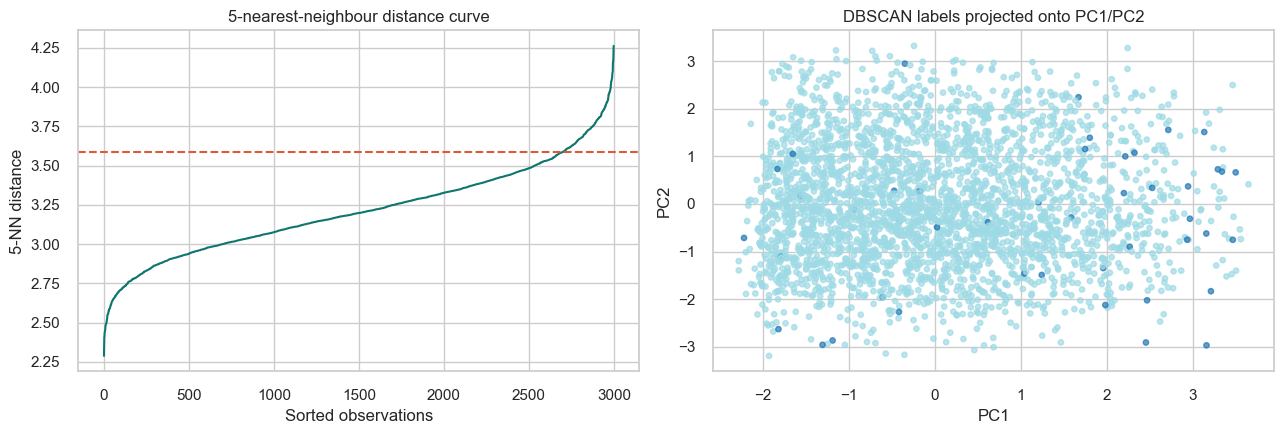

In [ ]:
point_a, point_b = np.array([1.,2.,3.]), np.array([4.,0.,8.])
distance_demo = pd.Series({
    "Manhattan p=1": cityblock(point_a, point_b),
    "Euclidean p=2": euclidean(point_a, point_b),
    "Minkowski p=3": minkowski(point_a, point_b, p=3),
})
display(distance_demo.to_frame("distance"))

neighbors = NearestNeighbors(n_neighbors=5).fit(X_pca90)
k_distances = np.sort(neighbors.kneighbors(X_pca90)[0][:,-1])
dbscan_eps = float(np.quantile(k_distances, .90))
dbscan_labels = DBSCAN(eps=dbscan_eps, min_samples=5).fit_predict(X_pca90)
non_noise = dbscan_labels != -1
n_dbscan_clusters = len(set(dbscan_labels)) - (1 if -1 in dbscan_labels else 0)
dbscan_silhouette = (silhouette_score(X_pca90[non_noise], dbscan_labels[non_noise])
                     if n_dbscan_clusters >= 2 else np.nan)
print({"eps":round(dbscan_eps,4), "clusters":n_dbscan_clusters,
       "noise_points":int((~non_noise).sum()), "silhouette_excluding_noise":dbscan_silhouette})

fig, axes = plt.subplots(1,2,figsize=(13,4.5))
axes[0].plot(k_distances,color="#0f766e"); axes[0].axhline(dbscan_eps,color="#dc5a3c",ls="--")
axes[0].set(title="5-nearest-neighbour distance curve",xlabel="Sorted observations",ylabel="5-NN distance")
axes[1].scatter(X_pca90[:,0],X_pca90[:,1],c=dbscan_labels,cmap="tab20",s=15,alpha=.7)
axes[1].set(title="DBSCAN labels projected onto PC1/PC2",xlabel="PC1",ylabel="PC2")
plt.tight_layout(); plt.savefig(ARTIFACTS/"dbscan_diagnostic.png",dpi=160,bbox_inches="tight"); plt.show()

### PCA vs truncated SVD vs t-SNE

PCA is a centred linear projection maximizing variance. Truncated SVD factorizes $X\approx U_k\Sigma_kV_k^T$ without requiring explicit centring and is useful for sparse matrices. t-SNE is a non-linear visualization method that preserves local neighbour probabilities by minimizing a KL divergence; its global distances, axes and cluster sizes should not be over-interpreted.

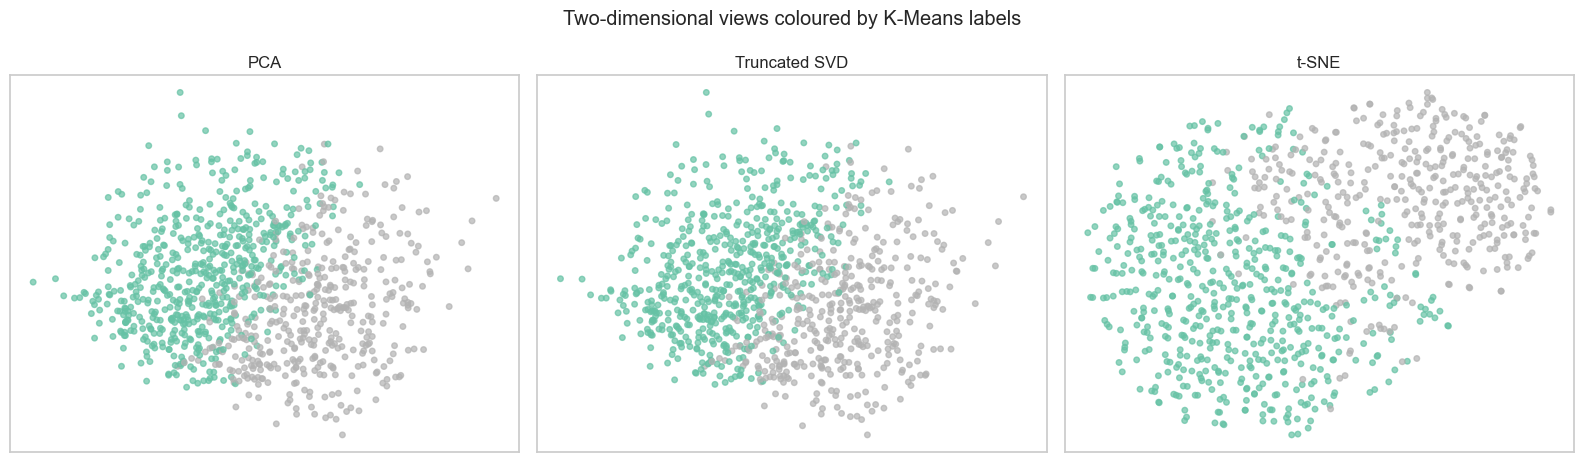

In [ ]:
sample_rng = np.random.default_rng(SEED)
sample_idx = sample_rng.choice(len(X_scaled), size=min(1000,len(X_scaled)), replace=False)
X_sample = X_scaled[sample_idx]
labels_sample = pca_cluster_labels[sample_idx]
pca_2d = PCA(n_components=2, random_state=SEED).fit_transform(X_sample)
svd_2d = TruncatedSVD(n_components=2, random_state=SEED).fit_transform(X_sample)
tsne_2d = TSNE(n_components=2, perplexity=30, learning_rate="auto", init="pca", n_iter=750, random_state=SEED).fit_transform(X_sample)

fig, axes = plt.subplots(1,3,figsize=(16,4.7))
for ax, embedding, title in zip(axes,[pca_2d,svd_2d,tsne_2d],["PCA","Truncated SVD","t-SNE"]):
    ax.scatter(embedding[:,0],embedding[:,1],c=labels_sample,cmap="Set2",s=16,alpha=.7)
    ax.set_title(title); ax.set_xticks([]); ax.set_yticks([])
plt.suptitle("Two-dimensional views coloured by K-Means labels")
plt.tight_layout(); plt.savefig(ARTIFACTS/"dimensionality_reduction_comparison.png",dpi=160,bbox_inches="tight"); plt.show()

### Popularity and content-based recommenders

Popularity uses aggregate behaviour and is a strong cold-start baseline. The Bayesian weighted score below prevents an item with one five-star rating from outranking established items. Content filtering uses item attributes; because the supplied ratings file has no item descriptions, a clearly labelled toy catalogue demonstrates TF-IDF cosine similarity without pretending those descriptions belong to the exam dataset.

In [ ]:
item_stats = ratings.groupby("ItemID").Rating.agg(["count","mean"])
prior = float(ratings.Rating.mean()); minimum_votes = float(item_stats["count"].quantile(.90))
item_stats["weighted_score"] = ((item_stats["count"]/(item_stats["count"]+minimum_votes))*item_stats["mean"] +
                                (minimum_votes/(item_stats["count"]+minimum_votes))*prior)
popularity_top10 = item_stats[item_stats["count"]>=minimum_votes].nlargest(10,"weighted_score")
display(popularity_top10.round(4))

toy_catalog = pd.DataFrame({
    "title":["Acoustic Guitar","Electric Guitar","Bass Guitar","Digital Piano","Drum Kit","Studio Microphone"],
    "description":["six string acoustic wood guitar","six string electric solid body guitar amplifier",
                   "four string electric bass guitar","weighted key digital piano keyboard",
                   "acoustic drum cymbal percussion set","condenser vocal recording studio microphone"],
})
tfidf = TfidfVectorizer(stop_words="english")
content_matrix = tfidf.fit_transform(toy_catalog.description)
similarity = cosine_similarity(content_matrix)
query_index = toy_catalog.index[toy_catalog.title=="Electric Guitar"][0]
neighbors_idx = np.argsort(similarity[query_index])[::-1][1:4]
content_recommendations = toy_catalog.loc[neighbors_idx,["title"]].copy()
content_recommendations["cosine_similarity"] = similarity[query_index,neighbors_idx]
display(content_recommendations)

,count,mean,weighted_score
ItemID,,,
B000RY68PA,119,4.9328,4.8794
B000QPHCB4,73,4.9452,4.8608
B00CK2FOZM,84,4.9286,4.8558
B0027842S4,151,4.8940,4.8537
B00FQ5F5MC,52,4.9615,4.8459
B0002F7ENY,51,4.9608,4.8433
B00HNVYUNW,154,4.8766,4.8381
B00CL1SR7O,63,4.9206,4.8280
B000QGE856,62,4.9194,4.8256


,title,cosine_similarity
2,Bass Guitar,0.467260
0,Acoustic Guitar,0.274621
5,Studio Microphone,0.000000


## Final results and inferences

- PCA reduces 20 standardized features to the minimum dimension retaining 90% variance.
- The selected $k$ is the best among the tested candidates, but its low silhouette warns against claiming strong natural segments.
- Cophenetic correlation identifies which linkage best preserves pairwise distances; this need not be the most useful business segmentation.
- The Apriori answer at 10% support is empty for lift>2. The 3% sensitivity result is reported separately and transparently.
- The recommender reports three-fold RMSE and top-five unseen items for a reproducibly selected active user.

In [ ]:
summary = {
    "mobile_rows": int(len(mobile_raw)),
    "pca_components_90pct": int(n_components_90),
    "pca_retained_variance": float(pca90.explained_variance_ratio_.sum()),
    "best_k_tested": int(best_k),
    "best_silhouette": float(silhouette_by_k[best_k]),
    "best_cophenetic_linkage": cophenetic_table.iloc[0].linkage,
    "apriori_10pct_itemsets": int(len(frequent_10)),
    "apriori_10pct_rules_lift_gt2": int(len(rules_10)),
    "recommender_target_user": str(TARGET_USER),
    "recommender_mean_3fold_rmse": float(cv_results.RMSE.mean()),
    "saved_artifact_count": len(list(ARTIFACTS.iterdir())),
}
(ARTIFACTS / "run_summary.json").write_text(json.dumps(summary, indent=2))
print(json.dumps(summary, indent=2))

{
  "mobile_rows": 3000,
  "pca_components_90pct": 16,
  "pca_retained_variance": 0.9126839530977303,
  "best_k_tested": 2,
  "best_silhouette": 0.06811573197682126,
  "best_cophenetic_linkage": "single",
  "apriori_10pct_itemsets": 7,
  "apriori_10pct_rules_lift_gt2": 0,
  "recommender_target_user": "A2NYK9KWFMJV4Y",
  "recommender_mean_3fold_rmse": 0.927672867326276,
  "saved_artifact_count": 19
}


/Users/somenathmandal/anaconda3/lib/python3.11/site-packages/pandas/core/dtypes/cast.py:1641: DeprecationWarning: np.find_common_type is deprecated.  Please use `np.result_type` or `np.promote_types`.
See https://numpy.org/devdocs/release/1.25.0-notes.html and the docs for more information.  (Deprecated NumPy 1.25)
  return np.find_common_type(types, [])


What are the key applications of SVD ?

Singular Value Decomposition (SVD) is a matrix factorization technique used in unsupervised machine learning to identify hidden patterns, reduce dimensionality, and extract important features from large datasets.

SVD decomposes a matrix as:

A=UΣVT

Key applications of SVD:

1. Dimensionality Reduction: Reduces the number of features while preserving the most important information in the dataset.

2. Feature Extraction: Identifies hidden or latent features from high-dimensional data.

3. Recommendation Systems: Used in collaborative filtering to predict missing user ratings and recommend products or movies.

4. Noise Reduction: Removes less significant components to reduce noise and improve data quality.

5. Data Compression: Represents large matrices using fewer components, reducing storage requirements.

6. Document Clustering: Used in Latent Semantic Analysis (LSA) to identify hidden topics and relationships between documents.

7. Data Visualization: Reduces high-dimensional data into 2D or 3D representations for easier visualization.

Conclusion: SVD is an important technique in unsupervised learning because it helps in dimensionality reduction, discovering hidden patterns, data compression, and improving the efficiency of machine learning algorithms.




What is the use of Cophenetic correlation coefficient in clustering ?


The Cophenetic Correlation Coefficient is used to measure how well a hierarchical clustering dendrogram preserves the original distances between data points and helps select an appropriate clustering method.

Key uses of CCC:

1. Evaluating Clustering Quality: Measures how well the dendrogram represents the original distances between data points.

2. Comparing Distances: Compares the original distances between data points with the cophenetic distances obtained from the dendrogram.

3. Selecting Clustering Methods: Helps identify the most suitable hierarchical clustering method, such as single, complete, or average linkage.

4. Measuring Cluster Reliability: A higher CCC indicates that the dendrogram preserves the original distance relationships more accurately.

5. Comparing Dendrograms: Helps compare different hierarchical clustering results and select the better clustering structure.

Formula:

C
C
C
=
Cov
(
d
,
c
)/
σ
d
σ
c


Where:

d = Original pairwise distances.

c = Cophenetic distances from the dendrogram.

σ
d
,
σ
c
 = Standard deviations of the respective distances.

Interpretation:

CCC close to 1: Strong agreement; good representation.

CCC close to 0: Weak correlation.

CCC close to -1: Strong negative correlation.

What is Density Based Clustering? Explain DBScan advantages and its working steps. answer in single cell for 5 marks

## Density-Based Clustering (DBSCAN) – 5 Marks

Density-Based Clustering is an unsupervised machine learning technique that groups data points based on their density. It forms clusters where data points are closely packed together and separates points in low-density regions as noise or outliers. DBSCAN (Density-Based Spatial Clustering of Applications with Noise) is a popular density-based clustering algorithm. It uses two parameters: Epsilon (ε), which defines the maximum distance between neighbouring points, and MinPts, which specifies the minimum number of points required to form a dense region. Working Steps of DBSCAN: 1. Select the values of Epsilon (ε) and MinPts. 2. Choose an unvisited data point and find all neighbouring points within the Epsilon radius. 3. If the number of neighbours is greater than or equal to MinPts, mark it as a Core Point and form a cluster. 4. Expand the cluster by adding neighbouring points that satisfy the density condition. 5. If a point does not have enough neighbours, mark it as a Noise Point or outlier (it may later become a border point if reached by another cluster). Repeat the process until all points are visited. Advantages of DBSCAN: (1) It does not require specifying the number of clusters in advance. (2) It can identify clusters of different shapes and sizes. (3) It effectively detects noise and outliers. (4) It works well with spatial datasets. (5) It does not require labelled training data. Conclusion: DBSCAN is a useful clustering algorithm that groups densely connected data points and identifies outliers without requiring the number of clusters in advance.

How do you decide the appropriate number of clusters in Agglomerative Hierarchical Clustering ? 5 marks

## How to Decide the Appropriate Number of Clusters in Agglomerative Hierarchical Clustering? (5 Marks)

In Agglomerative Hierarchical Clustering, the appropriate number of clusters is decided by analysing the dendrogram and identifying the suitable level at which the data should be divided into clusters.

Methods to determine the number of clusters:

1. Dendrogram Analysis: A dendrogram is a tree-like diagram that shows how clusters are merged. By observing the dendrogram, we can decide where to cut it to obtain the required number of clusters.

2. Largest Vertical Distance: Identify the largest vertical gap between two successive merging levels in the dendrogram. Cutting the dendrogram at this gap helps determine a suitable number of clusters.

3. Silhouette Score: Measures how well each data point fits within its own cluster compared to other clusters. A higher silhouette score indicates better clustering.

4. Elbow Method: Calculate the within-cluster sum of squares (WCSS) for different numbers of clusters and select the point where the decrease starts slowing down.

5. Domain Knowledge: Choose the number of clusters based on the problem requirements and practical understanding of the dataset.

Conclusion: The appropriate number of clusters in Agglomerative Hierarchical Clustering can be determined using dendrogram analysis, silhouette score, elbow method, and domain knowledge. Among these, dendrogram analysis is the most commonly used method.

## Compare Supervised and Unsupervised Machine Learning (4 Marks)

Supervised and Unsupervised Learning are two major types of machine learning techniques.

| Supervised Learning | Unsupervised Learning |
| --- | --- |
| 1. Uses labelled data for training. | 1. Uses unlabelled data for training. |
| 2. Output or target variable is known. | 2. Output or target variable is unknown. |
| 3. Used for classification and regression. | 3. Used for clustering and dimensionality reduction. |
| 4. Learns from input-output examples. | 4. Identifies hidden patterns and relationships in data. |
| 5. Examples: Linear Regression, Decision Tree, SVM. | 5. Examples: K-Means, DBSCAN, PCA. |

Examples:

- Supervised Learning: Predicting house prices using previous house prices, sizes and locations.
- Unsupervised Learning: Grouping customers based on their purchasing behaviour without predefined categories.

Conclusion: Supervised learning predicts outcomes using labelled data, whereas unsupervised learning discovers hidden patterns and groups in unlabelled data.

## Steps for Cluster Formation Using K-Means Clustering (5 Marks)

K-Means Clustering is an unsupervised machine learning algorithm used to divide a dataset into K different clusters based on the similarity of data points. Each cluster has a centroid (mean point).

Steps involved in K-Means Clustering:

1. Choose the Number of Clusters (K): Decide the number of clusters to be formed in the dataset.

2. Initialize Centroids: Select K initial centroids randomly from the dataset.

3. Assign Data Points: Calculate the distance (usually Euclidean distance) between each data point and all centroids. Assign each point to its nearest centroid.

4. Update Centroids: Calculate the mean of all data points in each cluster and update the centroid position.

5. Repeat the Process: Repeat the assignment and centroid updating steps until the centroids stop changing or the clusters become stable.

6. Final Clusters: Once the algorithm converges, the final K clusters are formed.

Example: Suppose we have customer data based on age and income. K-Means can group customers into three clusters based on their similarities.

Conclusion: K-Means clustering groups similar data points into K clusters by repeatedly assigning points to the nearest centroid and updating centroid positions until convergence.

## Need for Linkage Methods and Comparison of Different Linkage Methods (4 Marks)

Need for Linkage Methods:

Linkage methods are used in Hierarchical Clustering to measure the distance between two clusters and decide which clusters should be merged at each step. They help determine how clusters are formed based on the similarity or distance between data points.

Comparison of Different Linkage Methods:

| Linkage Method | Description |
| --- | --- |
| 1. Single Linkage | Calculates the minimum distance between any two points from different clusters. It can form long, chain-like clusters. |
| 2. Complete Linkage | Calculates the maximum distance between any two points from different clusters. It produces compact and well-separated clusters. |
| 3. Average Linkage | Calculates the average distance between all pairs of points from two clusters. It provides balanced clusters. |
| 4. Ward's Linkage | Merges clusters that result in the minimum increase in within-cluster variance. It generally produces compact clusters. |

Conclusion: Linkage methods determine how distances between clusters are calculated in hierarchical clustering. Different methods produce different cluster shapes and structures.

## Calculation of Cluster Inertia

Given points in Cluster 1:

$$
(2,4),(3,4),(1,3),(2,5)
$$

Step 1: Calculate the centroid (mean).

$$
C_x=\frac{2+3+1+2}{4}=2
$$

$$
C_y=\frac{4+4+3+5}{4}=4
$$

Therefore, centroid = (2, 4).

Step 2: Calculate the squared distance of each point from the centroid.

| Point | Squared distance |
| --- | --- |
| (2,4) | $(2-2)^2+(4-4)^2=0$ |
| (3,4) | $(3-2)^2+(4-4)^2=1$ |
| (1,3) | $(1-2)^2+(3-4)^2=2$ |
| (2,5) | $(2-2)^2+(5-4)^2=1$ |

Step 3: Calculate cluster inertia.

Cluster inertia is the sum of squared distances of all points from their cluster centroid.

$$
\text{Inertia}=0+1+2+1
$$

$$
\boxed{\text{Inertia}=4}
$$

Final Answer: 4Conclusion: The cluster inertia of Cluster 1 is 4.

In [ ]:
how to find optimal number of clusters from dendogram

